#Práctica 4: Teachable Machine

#1. Implementa la clasificación con la imagen que pertenece claramente a una categoría

#2. Implementa la clasificación con una imagen ambigua, que puede ser de        cualquier categoría

#3. Implementa la clasificación con una imagen sin ninguna categoría del modelo

In [18]:
# Una alternativa que he encontrado a subir los archivos dentro del propio Colab
!wget -O keras_model.h5 "https://github.com/Nagatorista/PracticasOptativaJoseSanchez/raw/refs/heads/main/Practica4_TeachableMachine_Python/keras_model.h5"
!wget -O labels.txt "https://github.com/Nagatorista/PracticasOptativaJoseSanchez/raw/refs/heads/main/Practica4_TeachableMachine_Python/labels.txt"
!wget -O imagen_clara.jpg "https://github.com/Nagatorista/PracticasOptativaJoseSanchez/raw/refs/heads/main/Practica4_TeachableMachine_Python/imagen_clara.jpg"
!wget -O imagen_ambigua.jpg "https://github.com/Nagatorista/PracticasOptativaJoseSanchez/raw/refs/heads/main/Practica4_TeachableMachine_Python/imagen_ambigua.jpg"
!wget -O imagen_sinCategoria.jpg "https://github.com/Nagatorista/PracticasOptativaJoseSanchez/raw/refs/heads/main/Practica4_TeachableMachine_Python/imagen_sinCategoria.jpg"

print("¡Archivos descargados correctamente desde GitHub!")

--2026-11-04 11:59:28--  https://github.com/Nagatorista/PracticasOptativaJoseSanchez/raw/refs/heads/main/Practica4_TeachableMachine_Python/keras_model.h5
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Nagatorista/PracticasOptativaJoseSanchez/refs/heads/main/Practica4_TeachableMachine_Python/keras_model.h5 [following]
--2026-11-04 11:59:28--  https://raw.githubusercontent.com/Nagatorista/PracticasOptativaJoseSanchez/refs/heads/main/Practica4_TeachableMachine_Python/keras_model.h5
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2453432 (2.3M) [application/octet-stream]
Saving to: ‘keras_model.h5’

1/1 [==============================] - 1s 511ms/step
Class: Raton
Confidence Score: 0.9999962


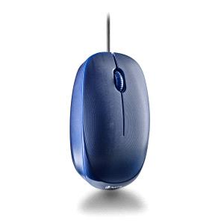

In [19]:
# Se modifican ciertos aspectos del código por incompatibilidades entre Kera 3 y el archivo .h5
!pip install -q tf_keras

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tf_keras as tfk
from PIL import Image, ImageOps
import numpy as np
from IPython.display import display

np.set_printoptions(suppress=True)

model = tfk.models.load_model(
    "keras_model.h5",
    compile=False
)

class_names = open("labels.txt", "r").readlines()

data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

image = Image.open("imagen_clara.jpg").convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

image_array = np.asarray(image)

normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)
# Mostramos la imagen
display(image)

1/1 [==============================] - 0s 24ms/step
Class: Raton
Confidence Score: 0.70406955


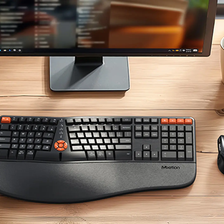

In [20]:
image = Image.open("imagen_ambigua.jpg").convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

image_array = np.asarray(image)

normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)
display(image)

1/1 [==============================] - 0s 27ms/step
Class: Raton
Confidence Score: 0.9921942


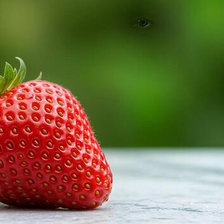

In [21]:
image = Image.open("imagen_sinCategoria.jpg").convert("RGB")

size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

image_array = np.asarray(image)

normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

data[0] = normalized_image_array

prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)
display(image)